In [12]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid", palette="muted")
REPORTS = Path("../reports")
REPORTS.mkdir(exist_ok=True)

print("Libraries Loaded Successfully")

Libraries Loaded Successfully


In [13]:
from pathlib import Path

# Project folders
raw = Path("../data/raw")
processed = Path("../data/processed")

# Load datasets
fund_master = pd.read_csv(raw / "01_fund_master.csv")
nav = pd.read_csv(processed / "02_nav_history_clean.csv")
aum = pd.read_csv(raw / "03_aum_by_fund_house.csv")
sip = pd.read_csv(raw / "04_monthly_sip_inflows.csv")
category = pd.read_csv(raw / "05_category_inflows.csv")
folio = pd.read_csv(raw / "06_industry_folio_count.csv")
performance = pd.read_csv(processed / "07_scheme_performance_clean.csv")
transactions = pd.read_csv(processed / "08_investor_transactions_clean.csv")
holdings = pd.read_csv(raw / "09_portfolio_holdings.csv")
benchmark = pd.read_csv(raw / "10_benchmark_indices.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [14]:
datasets = {
    "Fund Master": fund_master,
    "NAV History": nav,
    "AUM": aum,
    "SIP": sip,
    "Category": category,
    "Folio": folio,
    "Performance": performance,
    "Transactions": transactions,
    "Holdings": holdings,
    "Benchmark": benchmark
}

for name, df in datasets.items():
    print(f"{name:<25} {df.shape}")

Fund Master               (40, 15)
NAV History               (46000, 3)
AUM                       (90, 5)
SIP                       (48, 6)
Category                  (144, 3)
Folio                     (21, 6)
Performance               (40, 19)
Transactions              (32778, 13)
Holdings                  (322, 8)
Benchmark                 (8050, 3)


In [15]:
# Convert date column to datetime
nav["date"] = pd.to_datetime(nav["date"])

# Check
nav.head()

,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639


In [16]:
# Merge NAV history with fund names
nav_plot = nav.merge(
    fund_master[["amfi_code", "scheme_name"]],
    on="amfi_code",
    how="left"
)

nav_plot.head()

,amfi_code,date,nav,scheme_name
0,100016,2022-01-03,520.4608,HDFC Top 100 Fund - Regular Plan - Growth
1,100016,2022-01-04,515.0971,HDFC Top 100 Fund - Regular Plan - Growth
2,100016,2022-01-05,521.7239,HDFC Top 100 Fund - Regular Plan - Growth
3,100016,2022-01-06,515.7880,HDFC Top 100 Fund - Regular Plan - Growth
4,100016,2022-01-07,515.1639,HDFC Top 100 Fund - Regular Plan - Growth


# 1. Daily NAV Trend of Mutual Fund Schemes (2022–2026)

## Objective

Analyze the daily Net Asset Value (NAV) movement of mutual fund schemes between 2022 and 2026 to understand fund performance and market trends.

## Visualization

An interactive Plotly line chart displays the daily NAV movement for all mutual fund schemes. The chart also highlights the 2023 bull run and the 2024 market correction.

## Key Insight

Most mutual fund schemes show a steady upward trend in NAV over time. The highlighted regions indicate periods of strong market growth in 2023 and a market correction during 2024.


In [17]:
nav_plot.head()

,amfi_code,date,nav,scheme_name
0,100016,2022-01-03,520.4608,HDFC Top 100 Fund - Regular Plan - Growth
1,100016,2022-01-04,515.0971,HDFC Top 100 Fund - Regular Plan - Growth
2,100016,2022-01-05,521.7239,HDFC Top 100 Fund - Regular Plan - Growth
3,100016,2022-01-06,515.7880,HDFC Top 100 Fund - Regular Plan - Growth
4,100016,2022-01-07,515.1639,HDFC Top 100 Fund - Regular Plan - Growth


In [18]:
fig = px.line(
    nav_plot,
    x="date",
    y="nav",
    color="scheme_name",
    title="Daily NAV Trend of Mutual Fund Schemes (2022–2026)",
    labels={
        "date": "Date",
        "nav": "NAV (₹)",
        "scheme_name": "Scheme"
    }
)

fig.update_layout(
    width=1200,
    height=700,
    hovermode="x unified"
)

fig.write_image(
    "../reports/nav_trend.png",
    scale=3
)

fig.show()

In [19]:
fig.add_vrect(
    x0="2023-01-01",
    x1="2023-12-31",
    fillcolor="green",
    opacity=0.15,
    line_width=0,
    annotation_text="2023 Bull Run",
    annotation_position="top left"
)

fig.add_vrect(
    x0="2024-01-01",
    x1="2024-12-31",
    fillcolor="red",
    opacity=0.15,
    line_width=0,
    annotation_text="2024 Correction",
    annotation_position="top left"
)

In [20]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("../bluestock_mf.db")

print("Database connected successfully!")

Database connected successfully!


In [21]:
aum = pd.read_sql(
    "SELECT * FROM aum_by_fund_house",
    conn
)

aum.head()

,date,fund_house,aum_lakh_crore,aum_crore,num_schemes
0,2022-03-31,SBI Mutual Fund,6.05,605000,186
1,2022-03-31,ICICI Prudential MF,4.65,465000,216
2,2022-03-31,HDFC Mutual Fund,4.35,435000,195
3,2022-03-31,Nippon India MF,2.70,270000,177
4,2022-03-31,Kotak Mahindra MF,2.70,270000,168


In [22]:
print(aum.columns.tolist())

['date', 'fund_house', 'aum_lakh_crore', 'aum_crore', 'num_schemes']


In [23]:
print(aum.columns.tolist())

['date', 'fund_house', 'aum_lakh_crore', 'aum_crore', 'num_schemes']


In [24]:
aum["date"] = pd.to_datetime(aum["date"])
aum["year"] = aum["date"].dt.year

# 2. AUM Growth by Fund House (2022–2025)

## Objective

Analyze the growth in Assets Under Management (AUM) of major mutual fund houses between 2022 and 2025.

## Visualization

A grouped bar chart compares the AUM of different fund houses across multiple years.

## Key Insight

The chart highlights consistent growth in AUM across the industry. SBI Mutual Fund maintains the highest AUM throughout the period, indicating its strong market leadership.


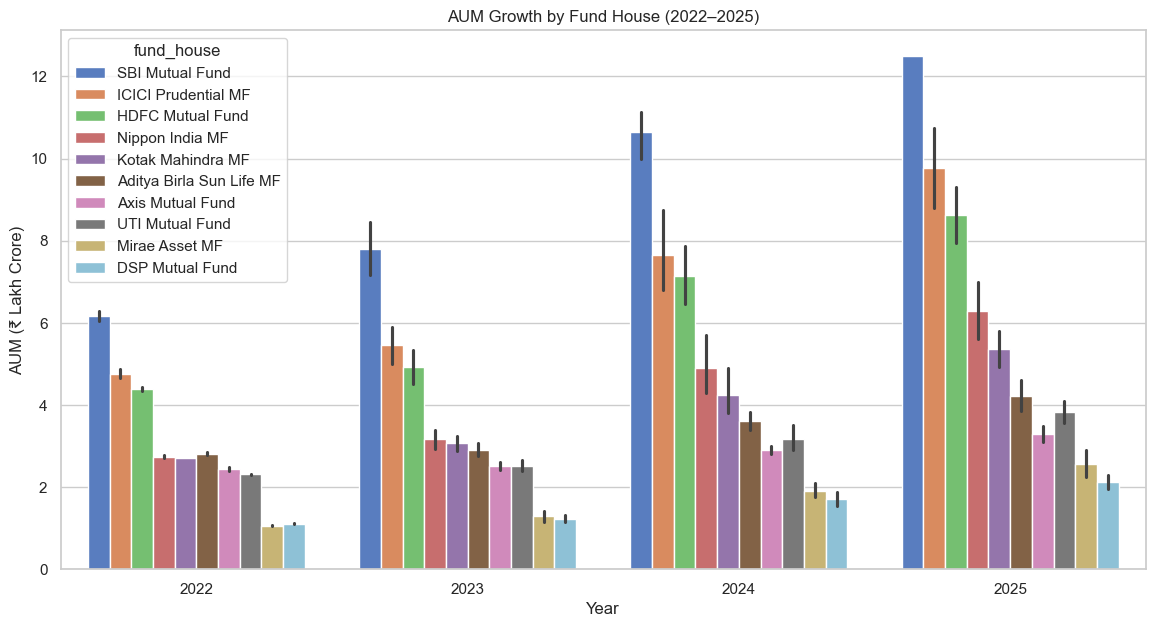

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

# Read table
aum = pd.read_sql(
    "SELECT * FROM aum_by_fund_house",
    conn
)

# Convert date to datetime
aum["date"] = pd.to_datetime(aum["date"])

# Extract year
aum["year"] = aum["date"].dt.year

# Plot
plt.figure(figsize=(14,7))

sns.barplot(
    data=aum,
    x="year",
    y="aum_lakh_crore",
    hue="fund_house"
)

plt.title("AUM Growth by Fund House (2022–2025)")
plt.xlabel("Year")
plt.ylabel("AUM (₹ Lakh Crore)")

plt.savefig("../reports/aum_growth.png", dpi=300, bbox_inches="tight")

plt.show()

In [26]:
aum.sort_values("aum_lakh_crore", ascending=False).head(10)

,date,fund_house,aum_lakh_crore,aum_crore,num_schemes,year
70,2025-03-31,SBI Mutual Fund,12.50,1250000,186,2025
80,2025-12-31,SBI Mutual Fund,12.50,1250000,186,2025
60,2024-12-31,SBI Mutual Fund,11.14,1114000,186,2024
50,2024-09-30,SBI Mutual Fund,10.80,1080000,186,2024
81,2025-12-31,ICICI Prudential MF,10.74,1074000,216,2025
40,2024-03-31,SBI Mutual Fund,10.00,1000000,186,2024
82,2025-12-31,HDFC Mutual Fund,9.30,930000,195,2025
71,2025-03-31,ICICI Prudential MF,8.80,880000,216,2025
61,2024-12-31,ICICI Prudential MF,8.74,874000,216,2024
30,2023-09-30,SBI Mutual Fund,8.45,845000,186,2023


In [27]:
sip = pd.read_sql(
    "SELECT * FROM monthly_sip_inflows",
    conn
)

sip.head()

,month,sip_inflow_crore,active_sip_accounts_crore,new_sip_accounts_lakh,sip_aum_lakh_crore,yoy_growth_pct
0,2022-01,11517,4.91,9.10,4.80,NaN
1,2022-02,11438,4.93,8.20,4.85,NaN
2,2022-03,12328,5.09,10.50,5.01,NaN
3,2022-04,11863,5.48,9.52,5.12,NaN
4,2022-05,12286,5.55,8.10,5.15,NaN


In [28]:
sip["month"] = pd.to_datetime(sip["month"])

# 3. Monthly SIP Inflow Trend (2022–2025)

## Objective

Analyze the monthly growth of Systematic Investment Plan (SIP) inflows from 2022 to 2025.

## Visualization

An interactive line chart displays monthly SIP inflows and highlights the overall investment trend.

## Key Insight

Monthly SIP inflows show a steady upward trend, reaching an all-time high of ₹31,002 crore in December 2025. This reflects growing investor confidence and increasing participation in mutual fund investments.


In [69]:
fig = px.line(
    sip,
    x="month",
    y="sip_inflow_crore",
    title="Monthly SIP Inflow Trend (2022–2025)",
    markers=True,
    labels={
        "month": "Month",
        "sip_inflow_crore": "SIP Inflow (₹ Crore)"
    }
)

fig.update_layout(
    width=1200,
    height=650,
    xaxis_tickangle=-45,    #rotate month labels
    hovermode="x unified"
)

fig.write_image(
    "../reports/sip_inflow_trend.png",
    scale=3
)

fig.show()

In [30]:
peak = sip.loc[sip["sip_inflow_crore"].idxmax()]

fig.add_annotation(
    x=peak["month"].strftime("%Y-%m-%d"),
    y=peak["sip_inflow_crore"],
    text="All-Time High<br>₹31,002 Cr<br>Dec 2025",
    showarrow=True,
    arrowhead=2,
    arrowsize=1.5,
    arrowwidth=2,
    ax=-40,
    ay=-60,
    bgcolor="yellow"
)

fig.show()

In [31]:
import sqlite3

conn = sqlite3.connect("../bluestock_mf.db")

In [32]:
category = pd.read_sql(
    "SELECT * FROM category_inflows",
    conn
)

category.head()

,month,category,net_inflow_crore
0,2024-04,Large Cap,2413.0
1,2024-04,Mid Cap,3897.0
2,2024-04,Small Cap,3533.0
3,2024-04,Flexi Cap,4947.0
4,2024-04,Large & Mid Cap,4214.0


In [33]:
pivot = category.pivot(
    index="category",
    columns="month",
    values="net_inflow_crore"
)

pivot

month,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03
category,,,,,,,,,,,,
ELSS,466.0,553.0,472.0,471.0,499.0,537.0,537.0,571.0,521.0,516.0,437.0,500.0
Flexi Cap,4947.0,5529.0,4478.0,4869.0,5562.0,5397.0,6004.0,6111.0,4654.0,5603.0,6068.0,4767.0
Gilt,784.0,836.0,864.0,959.0,952.0,925.0,898.0,704.0,831.0,744.0,942.0,956.0
Hybrid,2955.0,3487.0,3163.0,3291.0,3684.0,3015.0,3314.0,3264.0,3538.0,2967.0,3360.0,2830.0
Large & Mid Cap,4214.0,4368.0,4610.0,5023.0,5411.0,4528.0,4581.0,5556.0,4878.0,4816.0,5524.0,4243.0
Large Cap,2413.0,2076.0,2519.0,2574.0,1940.0,1879.0,2255.0,1870.0,1923.0,2025.0,1925.0,2234.0
Liquid,37537.0,41872.0,40486.0,34643.0,41952.0,35308.0,39091.0,40506.0,34933.0,33892.0,32374.0,38681.0
Mid Cap,3897.0,5300.0,5047.0,4548.0,3899.0,4960.0,4106.0,4336.0,5023.0,4316.0,4819.0,5061.0
Sectoral/Thematic,8052.0,8354.0,10030.0,9896.0,8360.0,8518.0,7680.0,7397.0,9820.0,7893.0,9215.0,8614.0


# 4. Category-wise Net Inflow Heatmap

## Objective

Examine the monthly net inflows across different mutual fund categories.

## Visualization

A heatmap displays fund categories on the Y-axis and months on the X-axis, with color intensity representing net inflow values.

## Key Insight

Liquid Funds consistently record the highest inflows, while equity-oriented categories such as Flexi Cap, Mid Cap, and Sectoral/Thematic also attract significant investments, indicating strong investor interest.


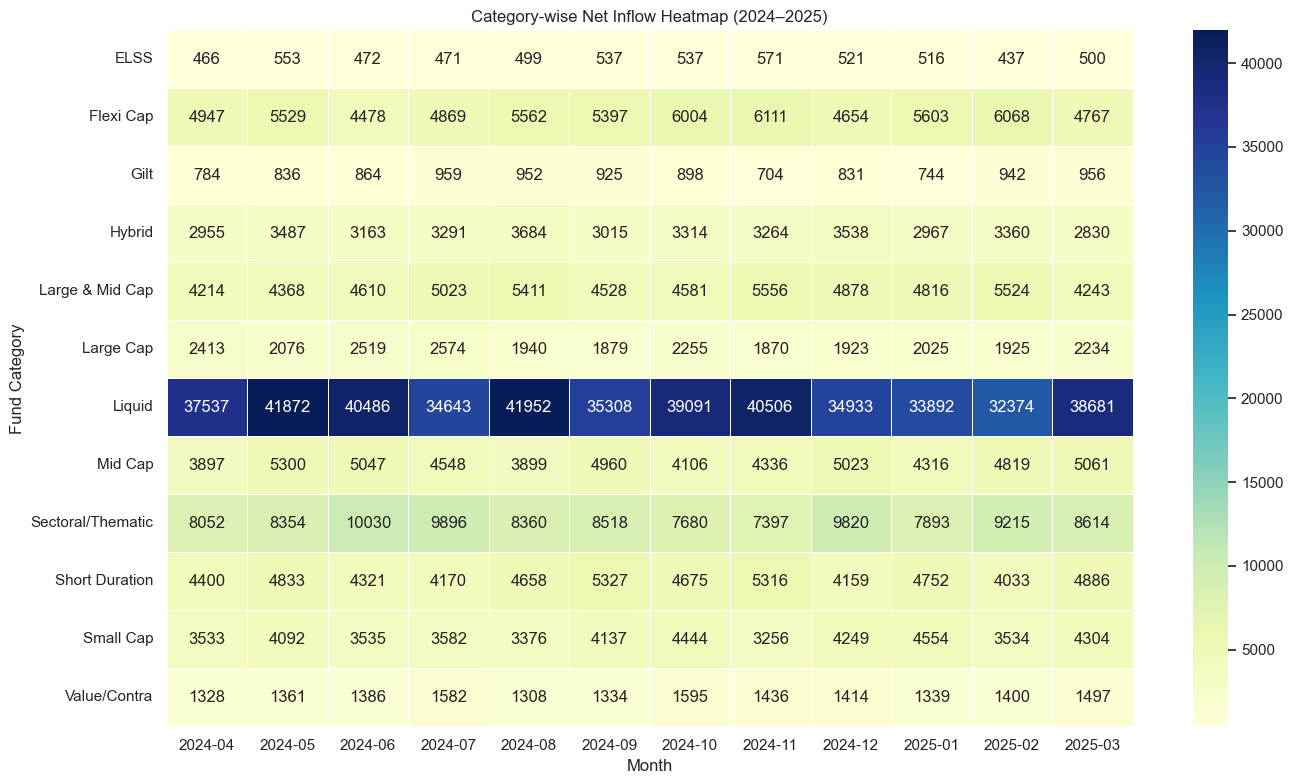

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 8))

sns.heatmap(
    pivot,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f",
    linewidths=0.5,
    linecolor="white"
)

plt.title("Category-wise Net Inflow Heatmap (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Fund Category")

plt.tight_layout()

plt.savefig(
    "../reports/category_inflow_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
print(pivot)

month              2024-04  2024-05  2024-06  2024-07  2024-08  2024-09  \
category                                                                  
ELSS                 466.0    553.0    472.0    471.0    499.0    537.0   
Flexi Cap           4947.0   5529.0   4478.0   4869.0   5562.0   5397.0   
Gilt                 784.0    836.0    864.0    959.0    952.0    925.0   
Hybrid              2955.0   3487.0   3163.0   3291.0   3684.0   3015.0   
Large & Mid Cap     4214.0   4368.0   4610.0   5023.0   5411.0   4528.0   
Large Cap           2413.0   2076.0   2519.0   2574.0   1940.0   1879.0   
Liquid             37537.0  41872.0  40486.0  34643.0  41952.0  35308.0   
Mid Cap             3897.0   5300.0   5047.0   4548.0   3899.0   4960.0   
Sectoral/Thematic   8052.0   8354.0  10030.0   9896.0   8360.0   8518.0   
Short Duration      4400.0   4833.0   4321.0   4170.0   4658.0   5327.0   
Small Cap           3533.0   4092.0   3535.0   3582.0   3376.0   4137.0   
Value/Contra        1328.

In [36]:
investor = pd.read_sql(
    "SELECT * FROM investor_transactions",
    conn
)

investor.head()

,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status
0,INV003054,2024-01-01,119092,Sip,1834,Telangana,Hyderabad,T30,56+,Female,77.1,UPI,Verified
1,INV002952,2024-01-01,148567,Redemption,392882,Punjab,Amritsar,B30,18-25,Male,7.1,Cheque,Verified
2,INV003420,2024-01-01,118636,Sip,912,Haryana,Faridabad,B30,36-45,Male,47.2,Mandate,Verified
3,INV003436,2024-01-01,118634,Sip,1102,Maharashtra,Mumbai,T30,36-45,Female,54.4,Cheque,Pending
4,INV004691,2024-01-01,119094,Lumpsum,8682,Delhi,Noida,T30,26-35,Male,14.5,Net Banking,Pending


In [37]:
print(investor.columns.tolist())

['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender', 'annual_income_lakh', 'payment_mode', 'kyc_status']


# 5. Investor Age Group Distribution

## Objective

Analyze the distribution of investors across different age groups.

## Visualization

A pie chart illustrates the percentage share of investors belonging to each age group.

## Key Insight

The chart identifies the age group contributing the largest share of investors, providing insights into the primary demographic participating in mutual fund investments.


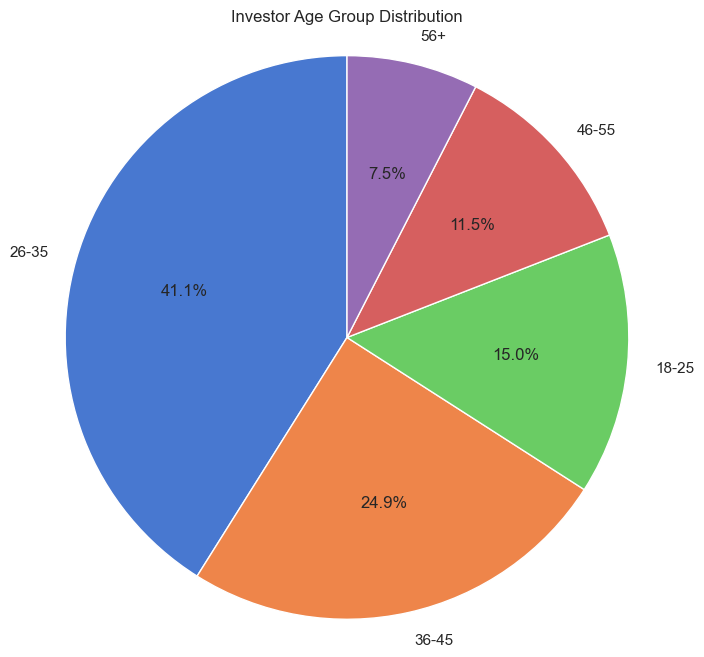

In [38]:
import matplotlib.pyplot as plt

# Count investors by age group

age_counts = investor["age_group"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
age_counts,
labels=age_counts.index,
autopct="%1.1f%%",
startangle=90
)

plt.title("Investor Age Group Distribution")
plt.axis("equal")

plt.savefig(
"../reports/investor_age_distribution.png",
dpi=300,
bbox_inches="tight"
)

plt.show()


# 6. SIP Amount Distribution by Age Group

## Objective

Analyze how SIP investment amounts vary across different age groups and identify the spread, median, and presence of outliers.

## Visualization

A box plot compares the distribution of investment amounts for each age group.

## Key Insight

The box plot highlights the median SIP amount, variability in investments, and any unusually high investment amounts (outliers) within each age group.


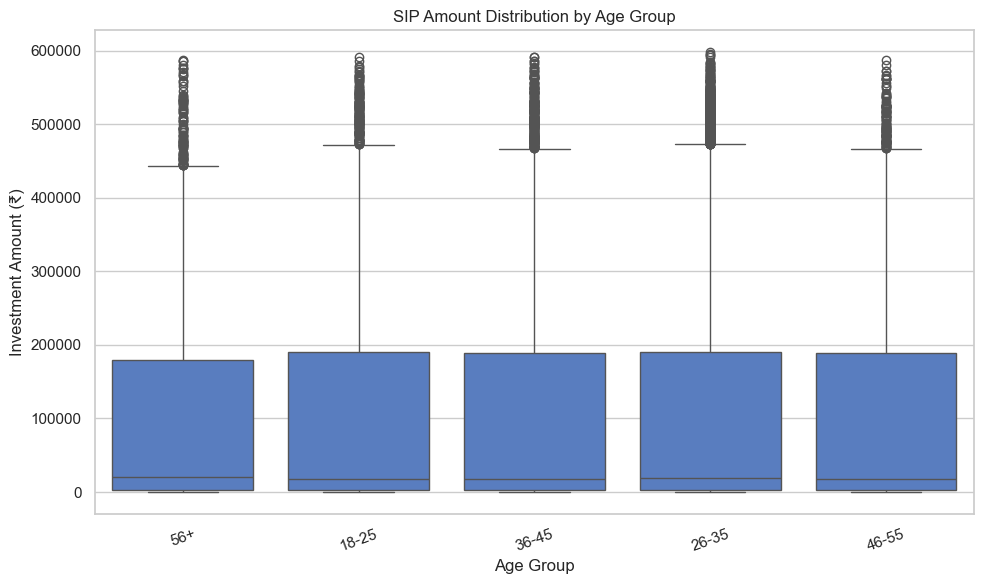

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.boxplot(
    data=investor,
    x="age_group",
    y="amount_inr",
    # showfliers=False
)

plt.title("SIP Amount Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Investment Amount (₹)")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    "../reports/sip_amount_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [40]:
investor.groupby("age_group")["amount_inr"].describe()

,count,mean,std,min,25%,50%,75%,max
age_group,,,,,,,,
18-25,4916.0,108144.709520,151765.866810,401.0,3038.75,17553.0,190858.0,590635.0
26-35,13463.0,107821.452722,150251.623816,400.0,3151.50,18523.0,190901.5,597498.0
36-45,8146.0,107003.133808,150402.614486,400.0,3170.00,17457.0,188750.0,591658.0
46-55,3779.0,107278.769251,150601.035638,400.0,3144.00,17425.0,188516.5,587530.0
56+,2474.0,105613.105497,148465.191753,406.0,3302.50,20396.5,179326.5,587757.0


# 7. Gender Distribution of Investors

## Objective

Analyze the gender-wise distribution of mutual fund investors to understand participation across different genders.

## Visualization

A pie chart illustrates the percentage share of investors by gender.

## Key Insight

Male investors account for approximately **66.5%** of the investor base, while **33.5%** are female investors. This indicates that male participation is nearly twice that of female participation in the dataset.



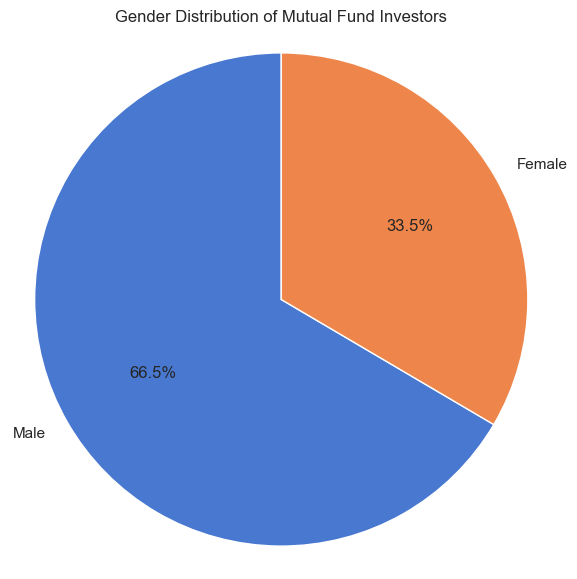

In [41]:
import matplotlib.pyplot as plt

# Count investors by gender
gender_counts = investor["gender"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Gender Distribution of Mutual Fund Investors")

plt.axis("equal")

plt.savefig(
    "../reports/gender_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 8. Geographic Distribution of SIP Investments by State

## Objective

Analyze the total SIP investment amount across different states to identify regions with the highest mutual fund participation.

## Visualization

A horizontal bar chart compares the total SIP investment amount across different states.

## Key Insight

Punjab records the highest total SIP investment amount among all states in the dataset, indicating strong investor participation. The chart also highlights how SIP investments are distributed across different regions of India.



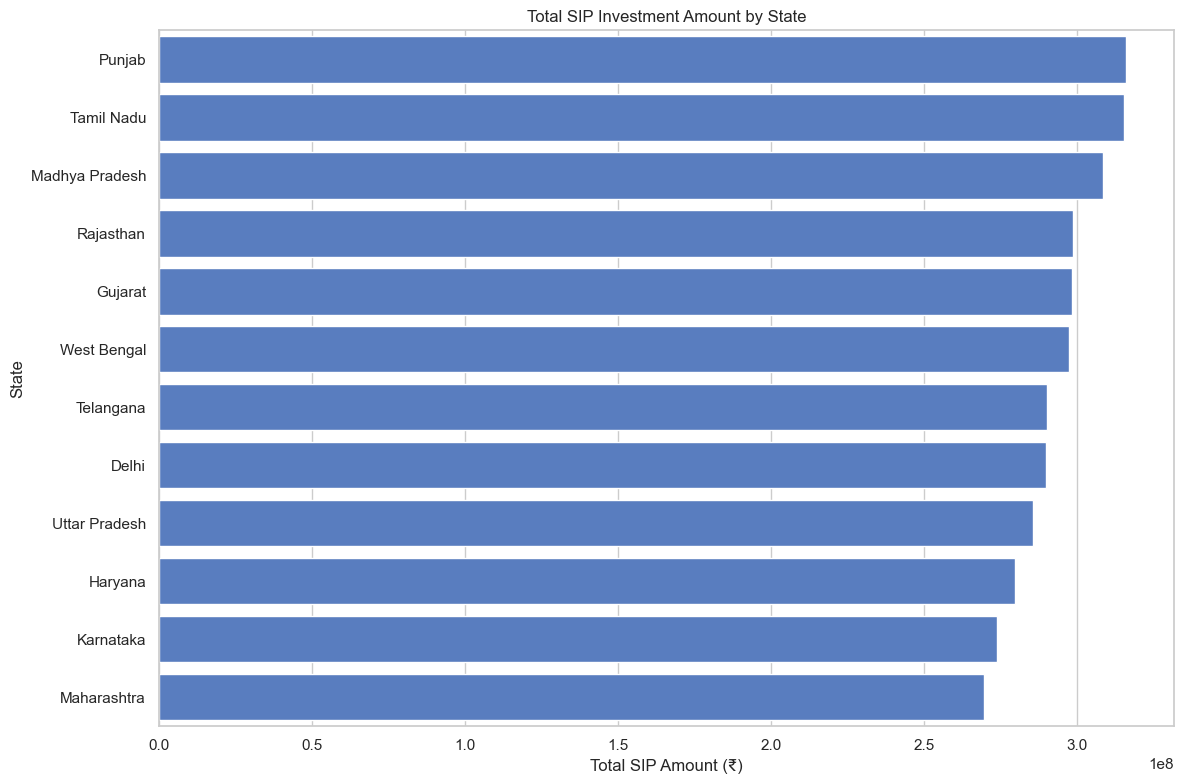

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

# Total SIP amount by state
state_sip = (
    investor.groupby("state")["amount_inr"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12,8))

sns.barplot(
    data=state_sip,
    y="state",
    x="amount_inr"
)

plt.title("Total SIP Investment Amount by State")
plt.xlabel("Total SIP Amount (₹)")
plt.ylabel("State")

plt.tight_layout()

plt.savefig(
    "../reports/state_wise_sip.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "../reports/state_wise_sip.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 9. T30 vs B30 City Tier Distribution

## Objective

Analyze the distribution of mutual fund investors across T30 (Top 30) and B30 (Beyond Top 30) cities.

## Visualization

A pie chart illustrates the percentage share of investors belonging to T30 and B30 city tiers.

## Key Insight

Approximately **66.3%** of investors belong to **T30 cities**, while **33.7%** belong to **B30 cities**. This indicates that metropolitan cities continue to dominate mutual fund participation, although B30 cities also contribute a significant share of investors.


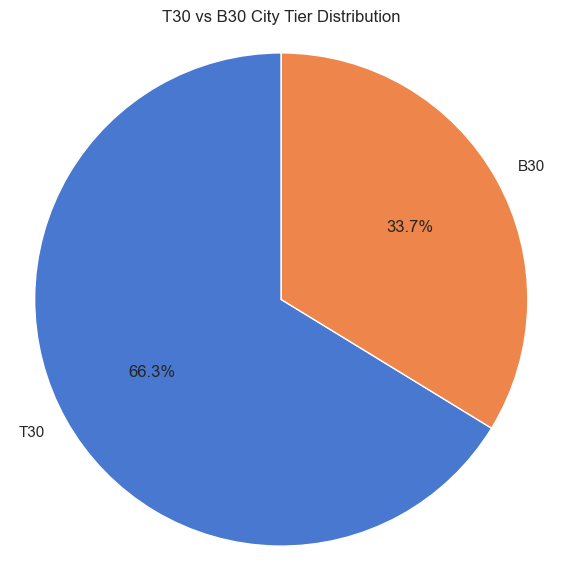

In [43]:
import matplotlib.pyplot as plt

# Count investors by city tier
city_tier_counts = investor["city_tier"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    city_tier_counts,
    labels=city_tier_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("T30 vs B30 City Tier Distribution")

plt.axis("equal")

plt.savefig(
    "../reports/t30_b30_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [44]:
folio = pd.read_sql(
    "SELECT * FROM industry_folio_count",
    conn
)

folio.head()

,month,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
0,2022-01,13.26,9.28,1.86,0.80,1.33
1,2022-04,13.91,9.74,1.95,0.83,1.39
2,2022-07,13.85,9.69,1.94,0.83,1.38
3,2022-10,14.12,9.88,1.98,0.85,1.41
4,2023-01,14.81,10.37,2.07,0.89,1.48


In [45]:
folio["month"] = pd.to_datetime(folio["month"])

In [46]:

print(folio.columns.tolist())

['month', 'total_folios_crore', 'equity_folios_crore', 'debt_folios_crore', 'hybrid_folios_crore', 'others_folios_crore']


In [47]:
folio.tail()

,month,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
16,2025-07-01,24.57,17.20,3.44,1.47,2.46
17,2025-08-01,24.89,17.42,3.48,1.49,2.49
18,2025-09-01,25.19,17.63,3.53,1.51,2.52
19,2025-10-01,25.60,17.92,3.58,1.54,2.56
20,2025-12-01,26.12,18.28,3.66,1.57,2.61


# 10. Mutual Fund Folio Count Growth (2022–2025)

## Objective

Analyze the growth in mutual fund folio counts between January 2022 and December 2025 to understand the increase in investor participation.

## Visualization

A Plotly line chart illustrates the growth in total mutual fund folios over time, with key milestones highlighted.

## Key Insight

Total mutual fund folios increased steadily over the analysis period, reflecting growing investor participation and wider adoption of mutual fund investments.


In [67]:
import plotly.express as px

fig = px.line(
    folio,
    x="month",
    y="total_folios_crore",
    markers=True,
    title="Growth in Mutual Fund Folio Count (2022–2025)",
    labels={
        "month": "Month",
        "total_folios_crore": "Total Folios (Crore)"
    }
)

fig.update_layout(
    width=1200,
    height=650,
    hovermode="x unified"
)

fig.write_image(
    "../reports/folio_growth.png",
    scale=3
)

fig.show()

In [49]:
fig.add_annotation(
    x="2022-01-01",
    y=13.26,
    text="13.26 Cr<br>Jan 2022",
    showarrow=True,
    arrowhead=2,
    bgcolor="lightgreen",
    ax=-30,
    ay=-50
)

In [50]:
fig.add_annotation(
    x="2025-12-01",
    y=26.12,
    text="26.12 Cr<br>Dec 2025",
    showarrow=True,
    arrowhead=2,
    bgcolor="yellow",
    ax=-30,
    ay=-60
)

In [51]:
nav = pd.read_sql(
    "SELECT * FROM nav_history",
    conn
)

nav.head()

,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639


In [52]:
print(nav.columns.tolist())

['amfi_code', 'date', 'nav']


# 11. NAV Return Correlation Matrix

## Objective

Analyze the correlation between daily NAV returns of selected mutual fund schemes to understand how similarly different funds move over time.

## Visualization

A Seaborn heatmap displays the pairwise correlation of daily NAV returns for ten selected mutual fund schemes.

## Key Insight

The heatmap reveals varying levels of correlation among the selected mutual fund schemes. Highly correlated funds tend to move together, whereas funds with lower correlations provide better diversification opportunities for investors.



In [53]:
nav["date"] = pd.to_datetime(nav["date"])

In [54]:
selected_codes = nav["amfi_code"].unique()[:10]

nav10 = nav[
    nav["amfi_code"].isin(selected_codes)
]

In [55]:
pivot = nav10.pivot(
    index="date",
    columns="amfi_code",
    values="nav"
)

pivot.head()

amfi_code,100016,100025,100033,101206,101207,101208,102885,102886,102887,118632
date,,,,,,,,,,
2022-01-03,520.4608,26.3169,107.3758,305.0996,38.5736,310.7415,89.8728,119.2905,191.0721,42.8339
2022-01-04,515.0971,26.2234,105.9447,305.4514,38.1545,310.6977,90.8724,120.6402,189.0737,42.8033
2022-01-05,521.7239,26.2221,105.4800,306.6324,38.1775,310.8165,90.1565,121.4580,188.0701,43.0564
2022-01-06,515.7880,26.1728,104.9350,305.9800,37.0665,310.7719,91.5338,125.2386,190.4545,43.2088
2022-01-07,515.1639,26.2261,104.3318,304.0480,37.9845,310.8388,90.6762,124.1321,187.3124,42.9585


In [56]:
returns = pivot.pct_change().dropna()

returns.head()

amfi_code,100016,100025,100033,101206,101207,101208,102885,102886,102887,118632
date,,,,,,,,,,
2022-01-04,-0.010306,-0.003553,-0.013328,0.001153,-0.010865,-0.000141,0.011122,0.011314,-0.010459,-0.000714
2022-01-05,0.012865,-0.000050,-0.004386,0.003866,0.000603,0.000382,-0.007878,0.006779,-0.005308,0.005913
2022-01-06,-0.011377,-0.001880,-0.005167,-0.002128,-0.029101,-0.000143,0.015277,0.031127,0.012678,0.003540
2022-01-07,-0.001210,0.002036,-0.005748,-0.006314,0.024766,0.000215,-0.009369,-0.008835,-0.016498,-0.005793
2022-01-10,-0.008639,0.006791,0.006277,0.011548,0.001251,0.000690,-0.001202,-0.000722,-0.011593,0.006360


In [57]:
corr = returns.corr()

corr

amfi_code,100016,100025,100033,101206,101207,101208,102885,102886,102887,118632
amfi_code,,,,,,,,,,
100016,1.000000,0.045567,-0.000006,0.027747,0.016053,-0.033773,-0.093533,-0.005867,-0.023316,-0.026781
100025,0.045567,1.000000,0.002150,0.023769,-0.006710,0.018455,-0.001038,0.013754,-0.005648,-0.014166
100033,-0.000006,0.002150,1.000000,-0.018079,0.000351,0.007864,-0.034228,-0.018166,-0.036647,-0.013318
101206,0.027747,0.023769,-0.018079,1.000000,0.010202,-0.027230,0.001570,0.007229,-0.006490,-0.005432
101207,0.016053,-0.006710,0.000351,0.010202,1.000000,-0.007530,-0.005929,0.004860,0.002304,0.043384
101208,-0.033773,0.018455,0.007864,-0.027230,-0.007530,1.000000,-0.001436,0.014307,0.036547,0.003507
102885,-0.093533,-0.001038,-0.034228,0.001570,-0.005929,-0.001436,1.000000,0.020691,-0.036704,-0.000285
102886,-0.005867,0.013754,-0.018166,0.007229,0.004860,0.014307,0.020691,1.000000,-0.007865,-0.039886
102887,-0.023316,-0.005648,-0.036647,-0.006490,0.002304,0.036547,-0.036704,-0.007865,1.000000,0.001248


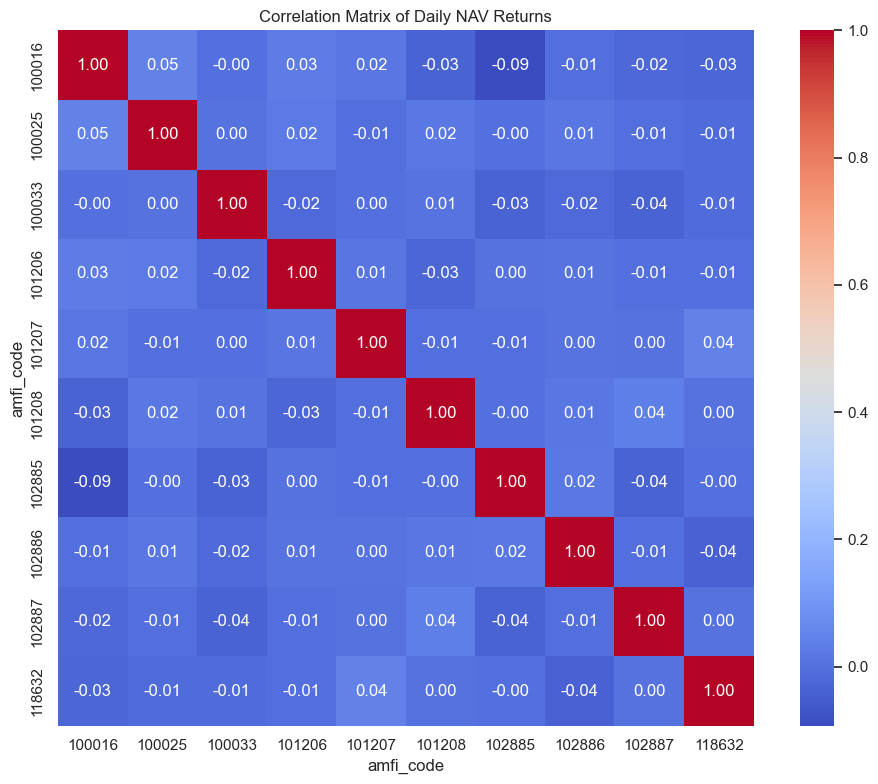

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True
)

plt.title("Correlation Matrix of Daily NAV Returns")

plt.tight_layout()

plt.savefig(
    "../reports/nav_return_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [59]:
holdings = pd.read_sql(
    "SELECT * FROM portfolio_holdings",
    conn
)

holdings.head()

,amfi_code,stock_symbol,stock_name,sector,weight_pct,market_value_cr,current_price_inr,portfolio_date
0,119551,POWERGRID,Power Grid Corporation,Utilities,13.85,737.09,6011.08,2025-12-31
1,119551,HDFCBANK,HDFC Bank Ltd,Banking,11.19,88.97,1074.65,2025-12-31
2,119551,GRASIM,Grasim Industries Ltd,Diversified,9.90,208.45,5964.59,2025-12-31
3,119551,DRREDDY,Dr. Reddy's Laboratories,Pharma,4.76,161.32,3748.82,2025-12-31
4,119551,ASIANPAINT,Asian Paints Ltd,Paints,10.25,725.90,1321.45,2025-12-31


In [60]:
print(holdings.columns.tolist())

['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct', 'market_value_cr', 'current_price_inr', 'portfolio_date']


# 12. Sector Allocation Across Equity Funds

## Objective

Analyze the overall sector allocation of mutual fund portfolios by aggregating sector weights across all equity funds.

## Visualization

A donut chart displays the percentage allocation of investments across different sectors.

## Key Insight

The Banking sector has the highest aggregate portfolio allocation, followed by IT and Pharma. This indicates that equity mutual funds in the dataset have a strong preference for financial services and technology companies, while maintaining diversified exposure across multiple sectors.


In [61]:
sector = (
    holdings.groupby("sector")["weight_pct"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

sector.head()

,sector,weight_pct
0,Banking,652.26
1,IT,455.47
2,Pharma,407.45
3,Automobile,323.65
4,Utilities,265.54


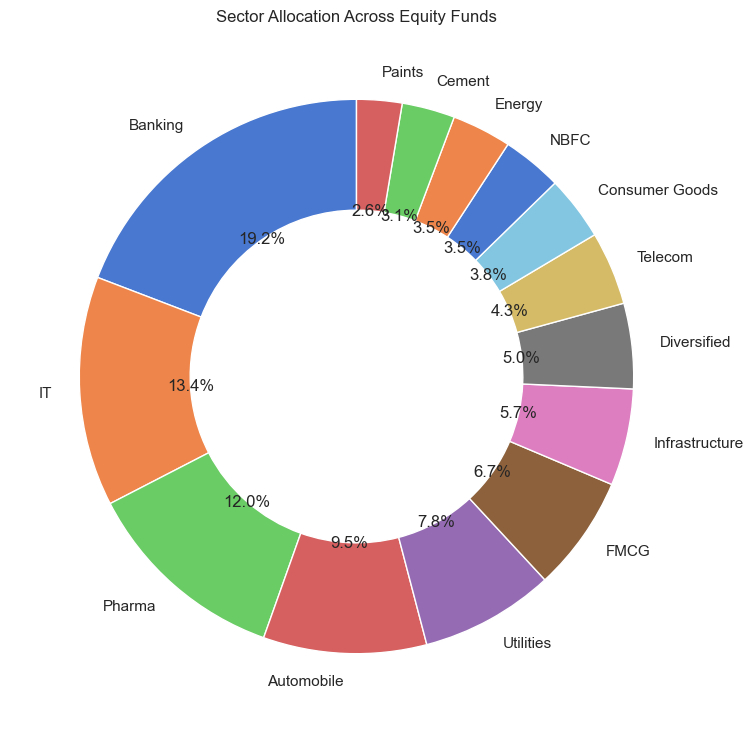

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,9))

plt.pie(
    sector["weight_pct"],
    labels=sector["sector"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width":0.4}
)

plt.title("Sector Allocation Across Equity Funds")

plt.savefig(
    "../reports/sector_allocation_donut.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 13. Transaction Type Distribution

## Objective

Analyze the distribution of mutual fund transaction types to understand investor activity patterns.

## Visualization

A bar chart displays the number of SIP, Lumpsum, and Redemption transactions recorded in the dataset.

## Key Insight

SIP transactions account for the largest share with **19,716** transactions, followed by **8,095** Lumpsum investments and **4,967** Redemptions. This indicates that investors prefer systematic investing through SIPs over one-time investments or withdrawals.


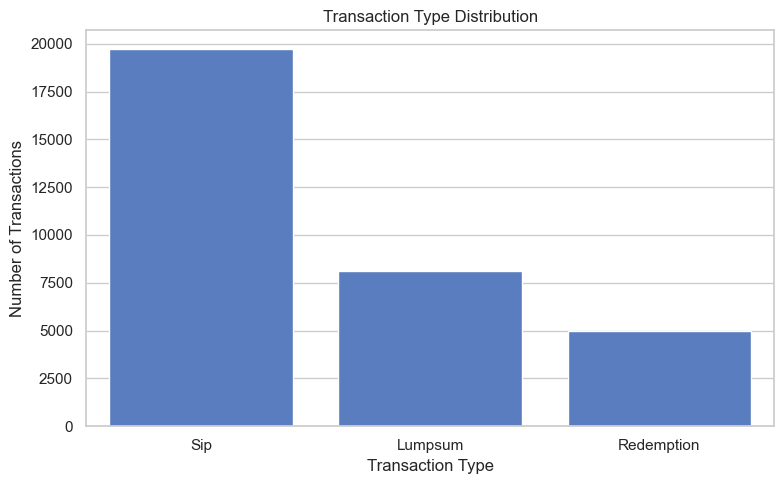

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count transaction types
transaction_counts = (
    investor["transaction_type"]
    .value_counts()
    .reset_index()
)

transaction_counts.columns = ["transaction_type", "count"]

plt.figure(figsize=(8,5))

sns.barplot(
    data=transaction_counts,
    x="transaction_type",
    y="count"
)

plt.title("Transaction Type Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.tight_layout()

plt.savefig(
    "../reports/transaction_type_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 14. Payment Mode Distribution

## Objective

Analyze the preferred payment methods used by investors for mutual fund transactions.

## Visualization

A bar chart compares the number of transactions made through different payment modes.

## Key Insight

Net Banking is the most frequently used payment mode with **8,250** transactions, followed closely by Cheque (**8,228**), UPI (**8,154**), and Mandate (**8,146**). The relatively balanced distribution indicates that investors use a variety of payment methods for mutual fund investments, with a slight preference for digital banking channels.


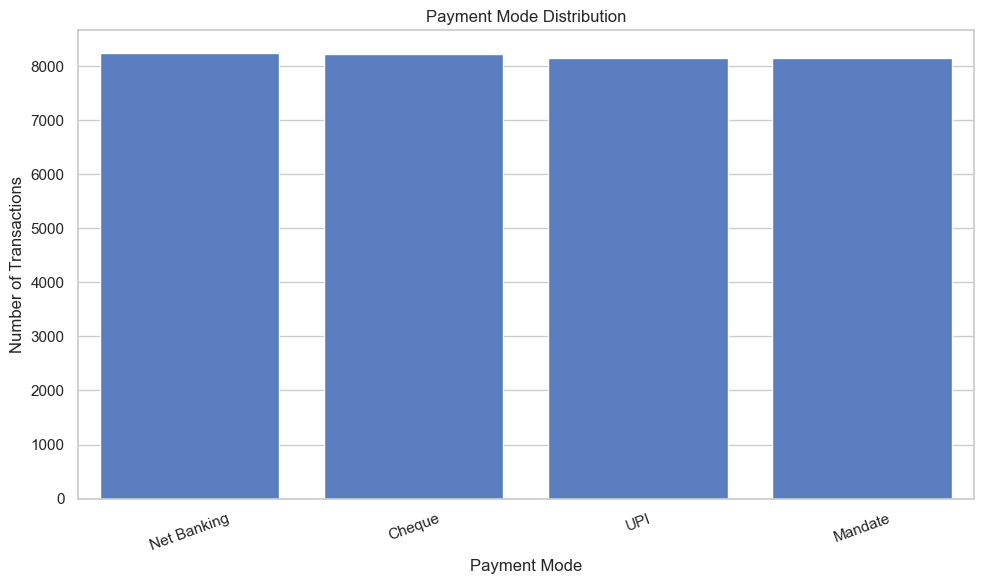

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count payment modes
payment_counts = (
    investor["payment_mode"]
    .value_counts()
    .reset_index()
)

payment_counts.columns = ["payment_mode", "count"]

plt.figure(figsize=(10,6))

sns.barplot(
    data=payment_counts,
    x="payment_mode",
    y="count"
)

plt.title("Payment Mode Distribution")
plt.xlabel("Payment Mode")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    "../reports/payment_mode_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 15. Annual Income Distribution of Investors

## Objective

Analyze the distribution of investors based on their annual income levels.

## Visualization

A histogram illustrates how investors are distributed across different annual income ranges.

## Key Insight

The average annual income of investors in the dataset is **₹26.18 lakh**, while the median income is **₹19.70 lakh**. Since the mean is higher than the median, the income distribution is positively skewed, indicating that a relatively small number of high-income investors raise the overall average.


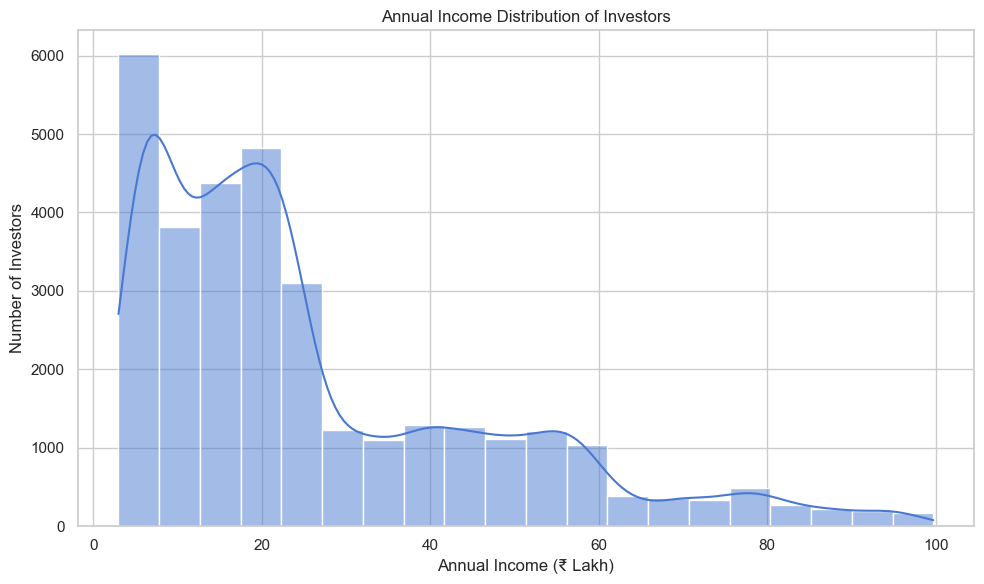

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.histplot(
    data=investor,
    x="annual_income_lakh",
    bins=20,
    kde=True
)

plt.title("Annual Income Distribution of Investors")
plt.xlabel("Annual Income (₹ Lakh)")
plt.ylabel("Number of Investors")

plt.tight_layout()

plt.savefig(
    "../reports/annual_income_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 16. KYC Status Distribution

## Objective

Analyze the Know Your Customer (KYC) compliance status of mutual fund investors.

## Visualization

A bar chart compares the number of investors with different KYC statuses.

## Key Insight

Out of **32,778** investors in the dataset, **30,146 (approximately 92%)** have completed KYC verification, while **2,632 (approximately 8%)** remain pending. This indicates a high level of regulatory compliance among mutual fund investors.


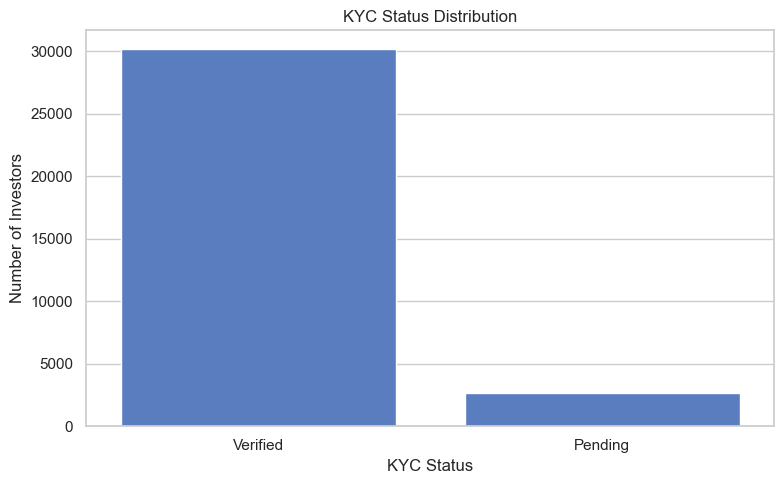

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count KYC status
kyc_counts = (
    investor["kyc_status"]
    .value_counts()
    .reset_index()
)

kyc_counts.columns = ["kyc_status", "count"]

plt.figure(figsize=(8,5))

sns.barplot(
    data=kyc_counts,
    x="kyc_status",
    y="count"
)

plt.title("KYC Status Distribution")
plt.xlabel("KYC Status")
plt.ylabel("Number of Investors")

plt.tight_layout()

plt.savefig(
    "../reports/kyc_status_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()